# MPIIGaze EDA

이 노트북은 MPIIGaze 데이터셋을 기반으로 EDA를 수행하는 예시입니다.

핵심 목표:
- 데이터 수와 사람별 구성을 확인한다.
- gaze / head pose 분포를 살펴본다.
- 눈 이미지 샘플을 시각화한다.
- 이상치와 편향을 확인한다.
- 이후 모델 학습을 위한 가설을 세운다.

In [3]:
import os
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt

%matplotlib inline

ROOT = Path.cwd()
LABEL_DIR = ROOT / 'data' / 'EyeBased' / 'MPIIGaze' / 'Label'
IMG_DIR = ROOT / 'data' / 'EyeBased' / 'MPIIGaze' / 'Image'

label_paths = sorted(LABEL_DIR.glob('*.label'))
print(f'Label files: {len(label_paths)}')
for p in label_paths:
    print(p.name)

Label files: 15
p00.label
p01.label
p02.label
p03.label
p04.label
p05.label
p06.label
p07.label
p08.label
p09.label
p10.label
p11.label
p12.label
p13.label
p14.label


In [4]:
def parse_label_file(path):
    with open(path, 'r') as f:
        lines = [line.strip() for line in f if line.strip()]
    if not lines:
        return []

    header = lines[0].split()
    rows = []
    for line in lines[1:]:
        parts = line.split()
        if len(parts) != len(header):
            continue
        row = dict(zip(header, parts))
        for key in ['2DGaze', '2DHead', '3DHead', 'Rmat', 'Smat', 'GazeOrigin']:
            if key in row:
                row[key] = np.array([float(x) for x in row[key].split(',')], dtype=np.float32)
        rows.append(row)
    return rows

records = []
for label_path in label_paths:
    person = label_path.stem
    rows = parse_label_file(label_path)
    for row in rows:
        img_name = row['Image']
        gaze = row['2DGaze']
        head = row['2DHead']
        eye = row['WhichEye']
        records.append({
            'person': person,
            'image_path': IMG_DIR / img_name,
            'gaze': gaze,
            'head': head,
            'eye': eye
        })

print(f'Total samples: {len(records)}')
person_counts = {}
for r in records:
    person_counts[r['person']] = person_counts.get(r['person'], 0) + 1

print('Samples per person:')
for p, c in sorted(person_counts.items()):
    print(f'  {p}: {c}')

Total samples: 45000
Samples per person:
  p00: 3000
  p01: 3000
  p02: 3000
  p03: 3000
  p04: 3000
  p05: 3000
  p06: 3000
  p07: 3000
  p08: 3000
  p09: 3000
  p10: 3000
  p11: 3000
  p12: 3000
  p13: 3000
  p14: 3000


In [5]:
gaze = np.stack([r['gaze'] for r in records], axis=0)
head = np.stack([r['head'] for r in records], axis=0)

print('Gaze stats:')
print('  yaw mean/std/min/max =', np.mean(gaze[:, 0]), np.std(gaze[:, 0]), np.min(gaze[:, 0]), np.max(gaze[:, 0]))
print('  pitch mean/std/min/max =', np.mean(gaze[:, 1]), np.std(gaze[:, 1]), np.min(gaze[:, 1]), np.max(gaze[:, 1]))

print('Head pose stats:')
print('  yaw mean/std/min/max =', np.mean(head[:, 0]), np.std(head[:, 0]), np.min(head[:, 0]), np.max(head[:, 0]))
print('  pitch mean/std/min/max =', np.mean(head[:, 1]), np.std(head[:, 1]), np.min(head[:, 1]), np.max(head[:, 1]))

Gaze stats:
  yaw mean/std/min/max = 0.0005801762 0.15162636 -0.7248519 0.67572933
  pitch mean/std/min/max = -0.15266484 0.090735815 -0.39730608 0.0831265
Head pose stats:
  yaw mean/std/min/max = -0.016897442 0.1457667 -0.894149 0.8169789
  pitch mean/std/min/max = 0.17015888 0.23471762 -0.7911314 0.97632843


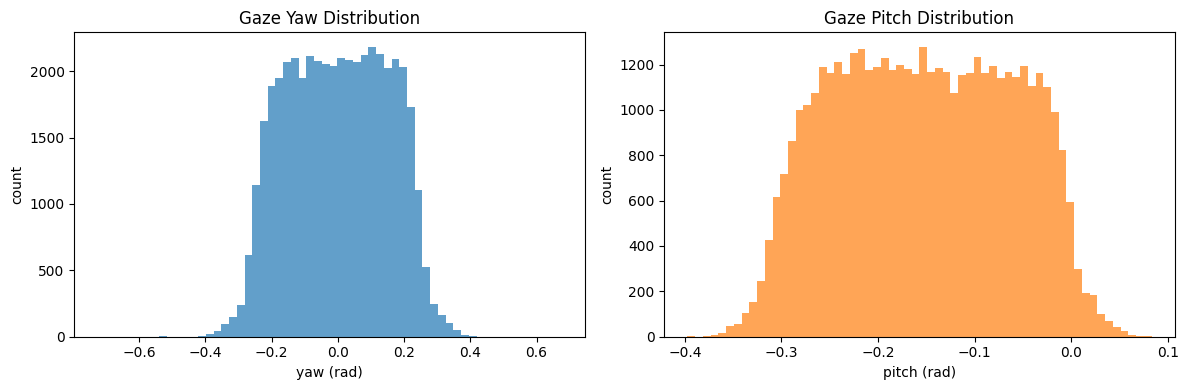

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(gaze[:, 0], bins=60, alpha=0.7, color='tab:blue')
axes[0].set_title('Gaze Yaw Distribution')
axes[0].set_xlabel('yaw (rad)')
axes[0].set_ylabel('count')

axes[1].hist(gaze[:, 1], bins=60, alpha=0.7, color='tab:orange')
axes[1].set_title('Gaze Pitch Distribution')
axes[1].set_xlabel('pitch (rad)')
axes[1].set_ylabel('count')

plt.tight_layout()
plt.show()

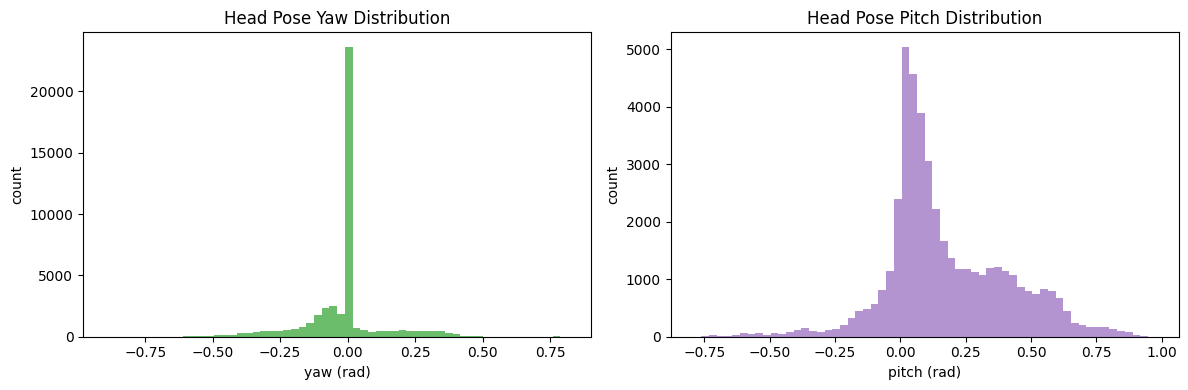

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(head[:, 0], bins=60, alpha=0.7, color='tab:green')
axes[0].set_title('Head Pose Yaw Distribution')
axes[0].set_xlabel('yaw (rad)')
axes[0].set_ylabel('count')

axes[1].hist(head[:, 1], bins=60, alpha=0.7, color='tab:purple')
axes[1].set_title('Head Pose Pitch Distribution')
axes[1].set_xlabel('pitch (rad)')
axes[1].set_ylabel('count')

plt.tight_layout()
plt.show()

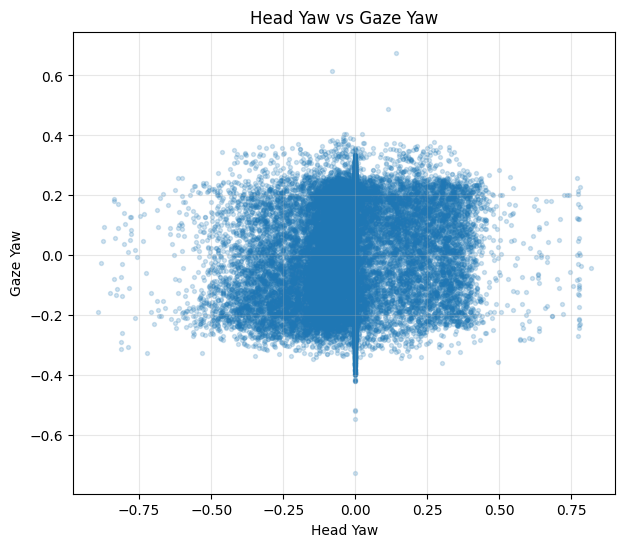

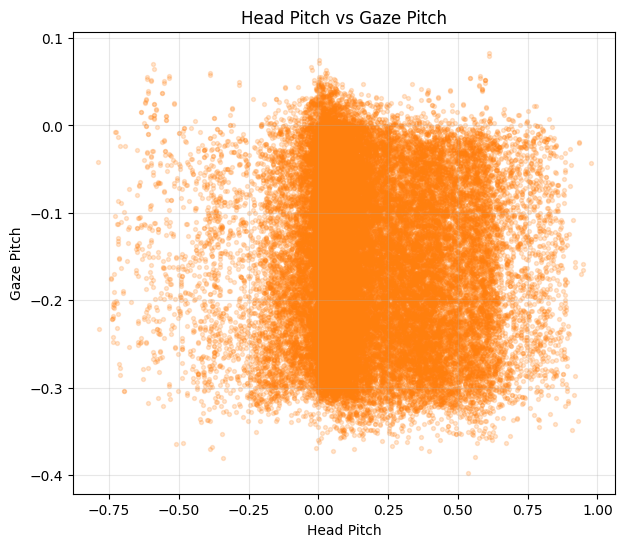

In [8]:
plt.figure(figsize=(7, 6))
plt.scatter(head[:, 0], gaze[:, 0], s=8, alpha=0.2, color='tab:blue')
plt.xlabel('Head Yaw')
plt.ylabel('Gaze Yaw')
plt.title('Head Yaw vs Gaze Yaw')
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(7, 6))
plt.scatter(head[:, 1], gaze[:, 1], s=8, alpha=0.2, color='tab:orange')
plt.xlabel('Head Pitch')
plt.ylabel('Gaze Pitch')
plt.title('Head Pitch vs Gaze Pitch')
plt.grid(alpha=0.3)
plt.show()

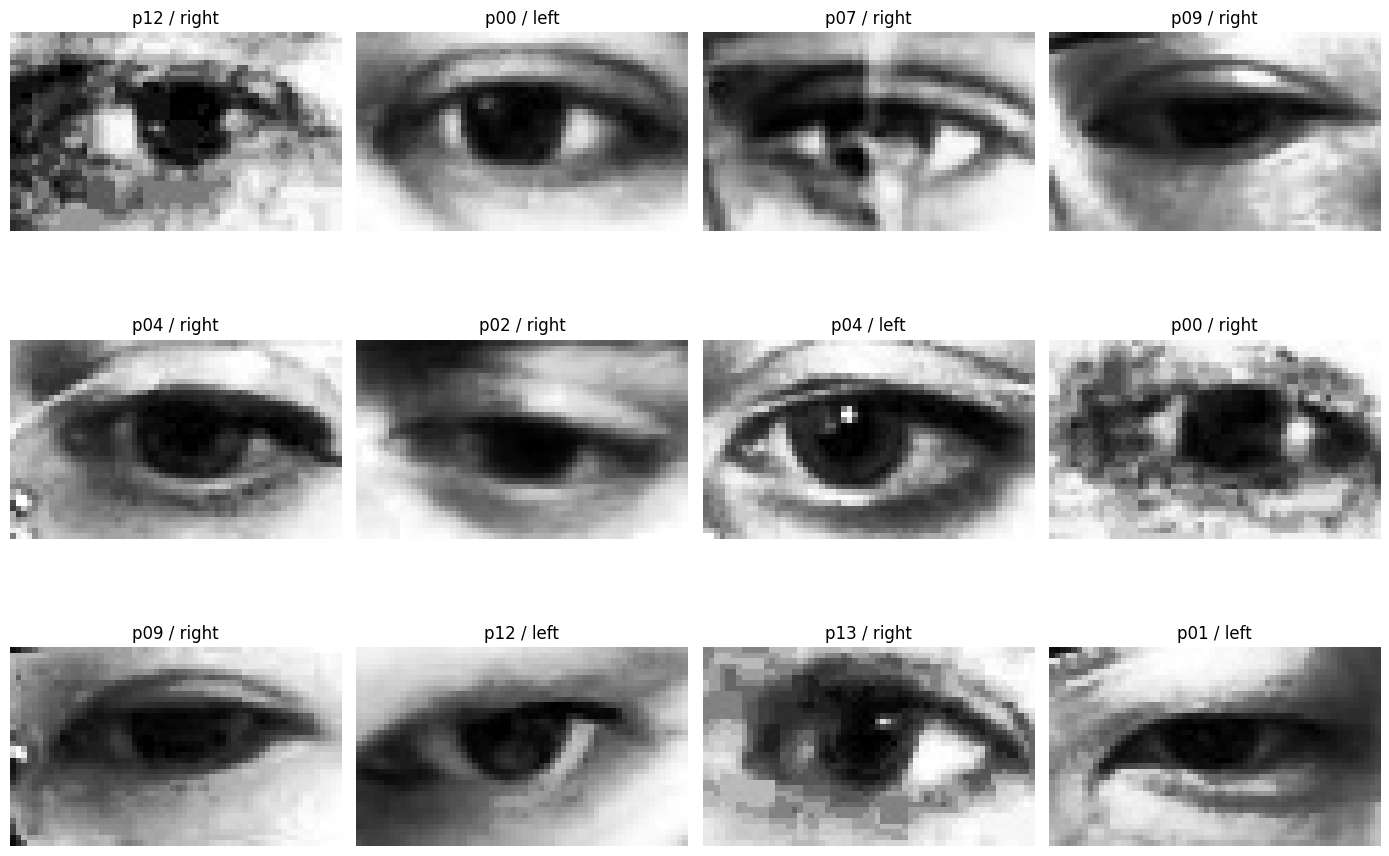

In [12]:
rng = np.random.default_rng(0)
sample_idx = rng.choice(len(records), size=12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

for ax, idx in zip(axes, sample_idx):
    rec = records[idx]
    img = cv2.imread(str(rec['image_path']), cv2.IMREAD_GRAYSCALE)
    if img is None:
        ax.text(0.5, 0.5, 'No image', ha='center', va='center')
        ax.set_axis_off()
        continue
    ax.imshow(img, cmap='gray')
    ax.set_title(f"{rec['person']} / {rec['eye']}")
    ax.set_axis_off()

for ax in axes[len(sample_idx):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [13]:
# 사람별 평균 gaze와 head pose 확인
person_stats = {}
for r in records:
    p = r['person']
    person_stats.setdefault(p, {'gaze': [], 'head': [], 'count': 0})
    person_stats[p]['gaze'].append(r['gaze'])
    person_stats[p]['head'].append(r['head'])
    person_stats[p]['count'] += 1

print('Person-wise summary:')
for p in sorted(person_stats):
    gaze_arr = np.stack(person_stats[p]['gaze'])
    head_arr = np.stack(person_stats[p]['head'])
    print(f"{p}: count={person_stats[p]['count']}, gaze_mean=({gaze_arr.mean(0)[0]:.3f}, {gaze_arr.mean(0)[1]:.3f}), head_mean=({head_arr.mean(0)[0]:.3f}, {head_arr.mean(0)[1]:.3f})")

Person-wise summary:
p00: count=3000, gaze_mean=(-0.007, -0.133), head_mean=(-0.016, 0.165)
p01: count=3000, gaze_mean=(-0.001, -0.166), head_mean=(-0.036, 0.194)
p02: count=3000, gaze_mean=(-0.003, -0.118), head_mean=(-0.017, 0.104)
p03: count=3000, gaze_mean=(0.008, -0.161), head_mean=(-0.033, 0.338)
p04: count=3000, gaze_mean=(0.000, -0.150), head_mean=(-0.056, 0.143)
p05: count=3000, gaze_mean=(0.005, -0.155), head_mean=(0.011, 0.148)
p06: count=3000, gaze_mean=(-0.004, -0.183), head_mean=(-0.063, 0.175)
p07: count=3000, gaze_mean=(-0.004, -0.166), head_mean=(-0.024, 0.443)
p08: count=3000, gaze_mean=(0.005, -0.174), head_mean=(-0.026, 0.255)
p09: count=3000, gaze_mean=(0.003, -0.158), head_mean=(-0.038, 0.123)
p10: count=3000, gaze_mean=(-0.001, -0.157), head_mean=(-0.066, 0.124)
p11: count=3000, gaze_mean=(0.001, -0.159), head_mean=(0.123, 0.057)
p12: count=3000, gaze_mean=(-0.000, -0.137), head_mean=(0.009, 0.116)
p13: count=3000, gaze_mean=(-0.000, -0.152), head_mean=(-0.027, 0

## EDA 결론

이 EDA를 통해 다음을 확인할 수 있습니다.

- 데이터는 15명(p00~p14), 각 사람당 약 3,000개씩 구성되어 있어 총 약 45,000개의 눈 이미지 샘플이 있다.
- 각 샘플은 정규화된 36×60 grayscale 눈 이미지와 gaze/head pose 라벨을 갖고 있다.
- gaze와 head pose는 모두 연속적인 값으로 분포되어 있고, 사람마다 평균값과 편차가 달라서 개인별 차이가 존재한다. 따라서 leave-one-person-out 평가가 적절하다.
- 눈 이미지 자체가 정규화되어 있고, 샘플이 균형적으로 존재하므로 모델 학습이 가능하다.
- baseline linear 실험 결과를 보면, image + 2DHead 평균 오차는 7.27°이고, image only는 7.28°로 거의 차이가 없다. 즉, 이 linear baseline에서는 head pose 정보가 거의 이득을 주지 못했다.

결론적으로, 이 데이터셋은 기본 baseline이 이미 어느 정도 동작하는 구조이지만, head pose를 효과적으로 활용하거나 개인 편차를 줄이는 방향으로 추가 실험을 진행해야 더 나은 성능을 얻을 수 있다.
